# Can a decoder tell the stimuli apart? — **real neurons**

Three two-object stimuli, two strict sub-populations of real neurons, and one question: how
well can each population tell each pair of stimuli apart?

| | stimulus | what it is |
|---|---|---|
| **A** | two objects antipodal | north and south |
| **B** | antipodal, rotated | the same pair, turned slightly clockwise |
| **C** | biased east | both objects nudged east, so the pair is no longer antipodal |

Writing a stimulus as $(\theta_0, \theta_1)$, the two comparisons probe **orthogonal**
directions of the local stimulus space:

$$\text{A}\to\text{B}:\ \Delta \propto (1,\,1)\quad\text{— the pair ROTATES, separation fixed}$$
$$\text{A}\to\text{C}:\ \Delta \propto (1,-1)\quad\text{— the SEPARATION changes, midpoint moves}$$

A **relational** neuron is tuned to $\theta_0 + \theta_1$, which is unchanged along $(1,-1)$,
so it should be good at A→B and poor at A→C. A retinotopic neuron is the other way round.

## The measure

Take the animal's **recorded** trials near each stimulus, fit a **linear** classifier, and report
how often it is right on held-out trials. No Gaussian approximation, no local linearity, no derivative.

The classifier is linear on purpose. The claim being tested is that the *population code*
separates the stimuli; a non-linear decoder could separate clouds that no downstream neuron
could read with a weighted sum.

A Fisher-information reading, $d'^2 = \Delta^\top J \Delta$, would be **local**, exact only for
small $\Delta$, and A→C moves the objects far enough that the expansion would be an assumption
rather than a fact. The decoder needs no such assumption, and it answers the question the text
actually asks.

**What the number is not.** Accuracy depends on how many trials the decoder is given. Read it as
a comparison *between populations at matched settings*: what the figure claims is the **pattern
across bars**, never a bar's height.

## Which neurons

Eligibility is the model-agnostic 2-object modulation criterion of
[`../../config.py`](../../config.py) applied by [`../selection_lib.py`](../selection_lib.py),
the same pool as figure 3's model comparison and motor decoder (the titration adds a
fit-strength cut, so it uses a subset). Within it, the two sub-populations are the `N_NEURONS`
neurons per animal that each model fits **best** — each neuron first assigned to whichever model
fits it better, so the two are **disjoint** and at **equal n** — see
[`decode_lib.py`](decode_lib.py) for what that rule is and why.


In [1]:
# ── CONFIG ───────────────────────────────────────────────────────────────────
# Which NEURONS are eligible is not set here. It is the model-agnostic 2-object modulation
# criterion of ../../config.py, applied by ../selection_lib.py: the same pool as the
# model comparison and motor decoder.

# ── The three stimuli: (theta_0, theta_1) in degrees, both objects on the ring ──
STIMULI_DEG = [
    (90, 270),      # A — antipodal, north/south
    (75, 255),      # B — the same pair, rotated 15 deg clockwise
    (75, 285),      # C — both nudged east: separation shrinks, midpoint fixed
]
STIM_LABELS = ['A', 'B', 'C']              # the short names used in the printouts and bars
STIM_TITLES = ['Stim. A', 'Stim. B', 'Stim. C']   # the titles over the three rings
PAIRS = [(0, 1), (0, 2)]        # A vs B (rotation), A vs C (separation change)

# ── The two strict sub-populations ───────────────────────────────────────────
N_NEURONS = 10      # per animal AND per side, so each bar is drawn from 2N neurons
# The two samples are the N neurons each model fits BEST (2 x its held-out excess
# accuracy over chance, `selection_lib.fit_strength`),
# not the extremes of rho. Each neuron is first assigned to whichever model fits it better and
# THEN ranked, so the samples stay disjoint; ranking the two columns independently overlaps
# 21% at N=100 and 42% at N=300, because a strongly driven neuron tends to be fit somewhat by
# both.

# ── Figures ──────────────────────────────────────────────────────────────────
FIGSIZE_STIMULI = (3.5, 1.6)
DISC_RADIUS, DISC_COLOR = 0.2, '0.6'
STIMULI_WSPACE, STIMULI_VIEW, STIMULI_TITLE_FONTSIZE = -0.2, 1.35, 14
# Title height, in axes fractions: 1.0 is the top of the (square, invisible) axes box and
# lower values slide the title down toward the ring. At STIMULI_VIEW = 1.35 the ring's top
# is near 0.87, so that is the floor before the text touches it.
STIMULI_TITLE_Y = 0.92

# ── The animal's recorded trials ─────────────────────────────────────────────
# A trial counts as stimulus X when BOTH of its objects are within REAL_TOL_DEG of the stimulus
# objects they match (whichever of the two pairings is better), and a pseudo-trial takes one
# real trial per unit — the units were recorded in different sessions, so there is no
# simultaneous population to take instead. The variability is then whatever the animal's
# neurons did, including everything a written-down noise model leaves out.
#
# What it costs: the stimuli are no longer exact. The animal was never shown A, only trials
# near it, so each class is a blur of radius REAL_TOL_DEG and the reported dist_*_deg says how
# big that blur actually is. A and B are only ~21 deg apart, so each trial is assigned to the
# NEARER of the pair -- otherwise the same trial would enter both classes.
#
# Eligibility radius, PER OBJECT. At 15 the median unit has ~20 eligible trials for each
# stimulus and the thinnest has 5, which is exactly DECODE_SPLITS: any tighter and a unit runs
# out of trials for a fold, and the run raises rather than quietly dropping that unit from the
# population. Watch n_pool_min in the table.
# A neuron needs DECODE_SPLITS trials within this radius of EVERY stimulus or it cannot be
# cross-validated; the selection skips such neurons and takes the next one down the ranking
# (`dl.enough_trials_mask`). That couples the population to the stimuli and to this radius:
# move a stimulus and a different set of neurons is eligible.
REAL_TOL_DEG = 15.0
REAL_N_TEST = 100        # pseudo-trials per class per fold in the held-out half

# ── The decoder ──────────────────────────────────────────────────────────────
DECODE_N_TRIALS = 200      # pseudo-trials PER stimulus in the training half
DECODE_SPLITS = 5          # stratified cross-validation folds
DECODE_SEED = 0
DECODE_C = 1.0             # L2 strength of the logistic regression

FIGSIZE_BARS = (2.9, 2.3)
REAL_COLORS  = ('tab:blue', 'tab:orange')      # retinotopic, relational
REAL_LABELS  = {'retinotopic': 'Retinotopic', 'relational': 'Relational'}
# The legend is one row of two entries (ncol=2), so what sets its WIDTH is the gap between
# the two columns -- `labelspacing` is vertical and does nothing at ncol=2. Shrink
# LEGEND_COLUMNSPACING to pull the entries together; it is in font-size units, so it also
# tightens automatically when LEGEND_FONTSIZE drops.
LEGEND_FONTSIZE = 12        # the paper's floor (figures/FORMATTING.md)
LEGEND_COLUMNSPACING = 0.6
LEGEND_KW = dict(ncol=2, borderpad=0.3, handlelength=1.0, handletextpad=0.4,
                 columnspacing=LEGEND_COLUMNSPACING, fontsize=LEGEND_FONTSIZE,
                 rounding_size=0.15, x=0.5)
# The error bars are over the cross-validation FOLDS -- how stable the fit is, not how uncertain the
# accuracy is over neurons or trials. The honest check on a close pair of bars is another seed.
BAR_YLIM = (0.4, 1.02)      # y limits of the bar axes
BAR_KW = dict(bar_width=0.36, error_lw=1.4, error_capsize=3.0)
# ─────────────────────────────────────────────────────────────────────────────

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.append(str(paths.FIGURES / 'figure_3'))
sys.path.append(str(paths.FIGURES))
sys.path.append(str(paths.FIGURES / 'figure_3/efficient_coding'))
import common

import decode_lib as dl         # THIS directory — selection, stimuli, decoder, figures
import pool_lib as pool         # ../efficient_coding — the pool and its response tables

common.set_style()

STIMULI = dl.stimulus_array(STIMULI_DEG)
DECODE_KW = dict(n_trials=DECODE_N_TRIALS, n_test=REAL_N_TEST, n_splits=DECODE_SPLITS,
                 seed=DECODE_SEED, C=DECODE_C)

## 1. The stimuli

The printout says what each comparison probes.

saved stimuli.pdf


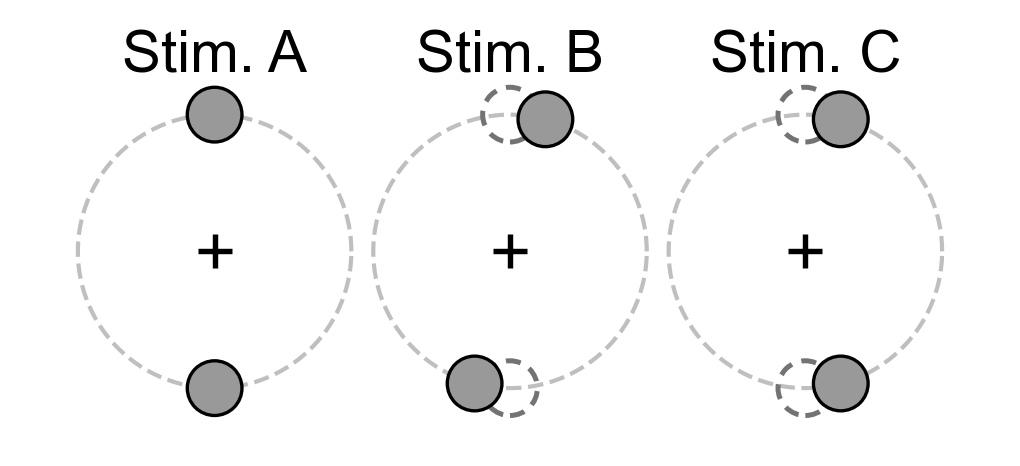

A → B: |Δ| = 21.2°, rotation -21.2°, separation change +0.0° (180° → 180° apart)
A → C: |Δ| = 21.2°, rotation +0.0°, separation change -21.2° (180° → 150° apart)


In [3]:
fig, _ = dl.plot_stimuli(STIMULI, STIM_TITLES, figsize=FIGSIZE_STIMULI,
                          disc_radius=DISC_RADIUS, disc_color=DISC_COLOR,
                          wspace=STIMULI_WSPACE, view=STIMULI_VIEW,
                          title_fontsize=STIMULI_TITLE_FONTSIZE,
                          title_y=STIMULI_TITLE_Y)
common.save(fig, 'stimuli.pdf')
plt.show()

for a, b in PAIRS:
    print(dl.describe_pair(STIMULI[a], STIMULI[b], (STIM_LABELS[a], STIM_LABELS[b])))

## 2. The two sub-populations

The `N_NEURONS` best-fit neurons of each model, per animal, pooled over the two animals.

In [4]:
rows = []
trials_by_side = {'retinotopic': [], 'relational': []}

# ONE ranking per animal: `n_per_side` is a number per animal, and each animal contributes its
# own top N so the two are represented evenly.
#
# `min_trials` makes the selection skip neurons that cannot be cross-validated — fewer than
# DECODE_SPLITS recorded trials within REAL_TOL_DEG of some stimulus — and take the next one
# down the strength ranking instead. Without it those neurons are selected and
# `decode_pair_real` raises rather than quietly leaving the two sides at unequal n.
for subject in dl.SUBJECTS:
    d = dl.select_wedges(subject, n_per_side=N_NEURONS, min_trials=DECODE_SPLITS,
                         stimuli=STIMULI, pairs=PAIRS, tol_deg=REAL_TOL_DEG)
    rep = dl.wedge_report(d['pop_df'], d['positions'])
    for side, p in d['positions'].items():
        # (t0, t1, fr) per unit, one entry per neuron of this side.
        trials_by_side[side] += pool.load_pool_trials(d['pop_df'].iloc[p])
        rows.append(dict(subject=subject, side=side, n=len(p),
                         median_rho=float(np.median(d['rho'][p])),
                         median_2obj_trials=float(rep.loc[side, 'n_2obj'])))

n = [len(t[0]) for v in trials_by_side.values() for t in v]
print(f'recorded trials per unit: median {int(np.median(n))} '
      f'(range {min(n)}-{max(n)}), before the {REAL_TOL_DEG:g}° eligibility cut')
display(pd.DataFrame(rows).round(3))
print({s: len(v) for s, v in trials_by_side.items()})
print(f'contributing: {sum(len(v) for v in trials_by_side.values())} distinct neurons')

  retinotopic : 10 of 356 (fit strength 0.343–0.431, median 0.368, 1 skipped for too few trials)
  relational  : 10 of 642 (fit strength 0.417–0.612, median 0.491)


ValueError: could not convert string to float: 'DMFC'

## 3. Decoding

One classifier per population and stimulus pair. Chance is **0.5** and is not a fitted
reference: the two classes are balanced by construction, so it is where a decoder that has
learnt nothing lands.

Each neuron enters **once**, facing the stimuli as drawn — no rotated replicas. The bars are
therefore a statement about the population that was recorded, at the stimuli in §1, and not
about an idealized rotation-invariant population built from it.

The responses are the animal's **recorded** trials: those within `REAL_TOL_DEG` of each
stimulus, one real trial per unit per pseudo-trial. The trial-to-trial scatter the decoder has
to see through is therefore whatever the neurons actually did, including everything a
written-down noise model leaves out. The cost is that the classes are a blur of radius
`REAL_TOL_DEG` rather than the stimuli themselves — `dist_*_deg` in the table reports how big
that blur is. What the figure claims is the *pattern* across bars, never a bar's height.


/opt/miniconda3/envs/wm_paper/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/miniconda3/envs/wm_paper/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/miniconda3/envs/wm_paper/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/miniconda3/envs/wm_paper/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/miniconda3/envs/wm_paper/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise 

,population,pair,n_units,accuracy,accuracy_sem,auc,n_features,n_pool_a,n_pool_b,n_pool_min,dist_a_deg,dist_b_deg
0,retinotopic,A vs B,20,0.627,0.0997,0.6534,20,21.0,12.0,5,10.9114,9.9631
1,retinotopic,A vs C,20,0.993,0.0037,0.9999,20,14.0,22.0,7,10.1781,9.0503
2,relational,A vs B,20,0.980,0.0164,0.9992,20,22.0,15.0,6,10.9574,9.7570
3,relational,A vs C,20,0.653,0.0791,0.7269,20,17.0,22.0,8,10.3974,8.5333


saved decoding.pdf


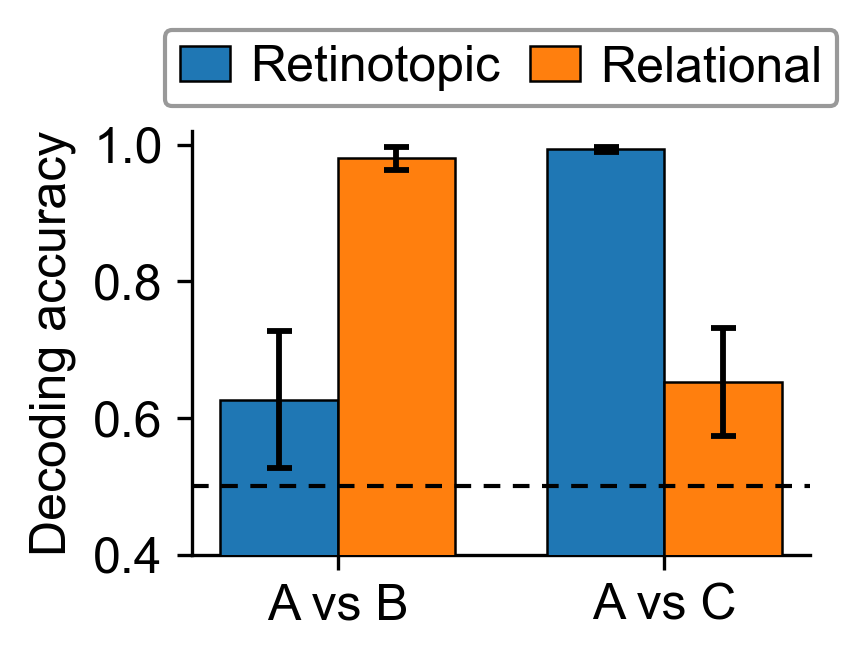

In [ ]:
dec = dl.decoding_table(STIMULI, PAIRS, STIM_LABELS, trials=trials_by_side,
                        tol_deg=REAL_TOL_DEG, **DECODE_KW)
display(dec.drop(columns='folds').round(4))

fig, _ = dl.plot_decoding(dec, labels=REAL_LABELS, colors=REAL_COLORS,
                          figsize=FIGSIZE_BARS, ylim=BAR_YLIM, legend_kw=LEGEND_KW,
                          **BAR_KW)
common.save(fig, 'decoding.pdf')
plt.show()
